In [1]:
import numpy as np
from scipy.stats import norm
import matplotlib.pyplot as plt

In [2]:
#a)
S0, K, T = 7685, 7750, 0.25
r = 4*np.log(1 + 0.03/4)
sigma_monthly = 0.04665167696027063  # estimated from your exercise 1 data
sigma = sigma_monthly * np.sqrt(12)

d1 = (np.log(S0/K) + (r + 0.5*sigma**2)*T) / (sigma*np.sqrt(T))
d2 = d1 - sigma*np.sqrt(T)
C = S0*norm.cdf(d1) - K*np.exp(-r*T)*norm.cdf(d2)

premium = C * 100 * 20
print(C, premium, sigma)

244.14549775997193 488290.9955199438 0.16160614950695826


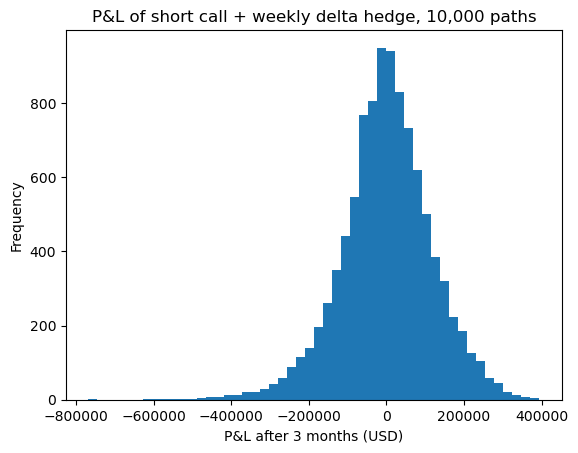

mean P&L = -38.71698608255717
std P&L  = 118369.0314366703


In [17]:
#b)
mu = 0.05
M = 2000
n_paths, n_steps = 10000, 13
dt = T / n_steps

# Simulate index paths
S = np.zeros((n_paths, n_steps + 1))
S[:, 0] = S0
for i in range(n_steps):
    Z = np.random.randn(n_paths)
    S[:, i + 1] = S[:, i] * np.exp((mu - 0.5 * sigma**2) * dt + sigma * np.sqrt(dt) * Z)

# Hedge at t = 0
d1 = (np.log(S0 / K) + (r + 0.5 * sigma**2) * T) / (sigma * np.sqrt(T))
delta = M * norm.cdf(d1) * np.ones(n_paths)
cash = M * C - delta * S0

# Weekly rebalancing
for i in range(1, n_steps):
    cash = cash * np.exp(r * dt)
    d1 = (np.log(S[:, i] / K) + (r + 0.5 * sigma**2) * (T - i * dt)) / (sigma * np.sqrt(T - i * dt))
    new_delta = M * norm.cdf(d1)
    cash = cash - (new_delta - delta) * S[:, i]
    delta = new_delta

# Maturity
cash = cash * np.exp(r * dt)
pnl = delta * S[:, -1] + cash - M * np.maximum(S[:, -1] - K, 0)

plt.hist(pnl, bins=50)
plt.xlabel("P&L after 3 months (USD)")
plt.ylabel("Frequency")
plt.title("P&L of short call + weekly delta hedge, 10,000 paths")
plt.show()

print("mean P&L =", np.mean(pnl))
print("std P&L  =", np.std(pnl))

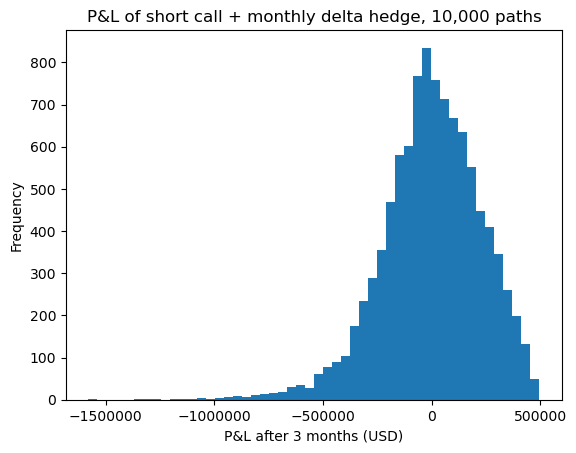

mean P&L = -1107.4868551641819
std P&L  = 229609.81474703757


In [23]:
#c)
mu = 0.05
M = 2000
n_paths, n_steps = 10000, 3
dt = T / n_steps

# Simulate index paths
S = np.zeros((n_paths, n_steps + 1))
S[:, 0] = S0
for i in range(n_steps):
    Z = np.random.randn(n_paths)
    S[:, i + 1] = S[:, i] * np.exp((mu - 0.5 * sigma**2) * dt + sigma * np.sqrt(dt) * Z)

# Hedge at t = 0
d1 = (np.log(S0 / K) + (r + 0.5 * sigma**2) * T) / (sigma * np.sqrt(T))
delta = M * norm.cdf(d1) * np.ones(n_paths)
cash = M * C - delta * S0

# Weekly rebalancing
for i in range(1, n_steps):
    cash = cash * np.exp(r * dt)
    d1 = (np.log(S[:, i] / K) + (r + 0.5 * sigma**2) * (T - i * dt)) / (sigma * np.sqrt(T - i * dt))
    new_delta = M * norm.cdf(d1)
    cash = cash - (new_delta - delta) * S[:, i]
    delta = new_delta

# Maturity
cash = cash * np.exp(r * dt)
pnl = delta * S[:, -1] + cash - M * np.maximum(S[:, -1] - K, 0)

plt.hist(pnl, bins=50)
plt.xlabel("P&L after 3 months (USD)")
plt.ylabel("Frequency")
plt.title("P&L of short call + monthly delta hedge, 10,000 paths")

plt.ticklabel_format(axis='x', style='plain', useOffset=False)

plt.show()

print("mean P&L =", np.mean(pnl))
print("std P&L  =", np.std(pnl))

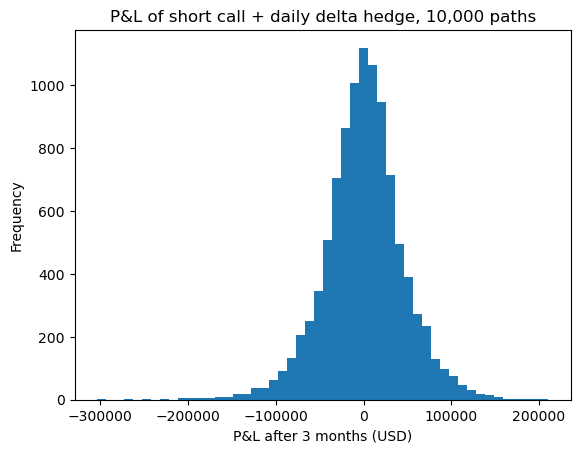

mean P&L = 239.9539448158685
std P&L  = 45278.95150645257


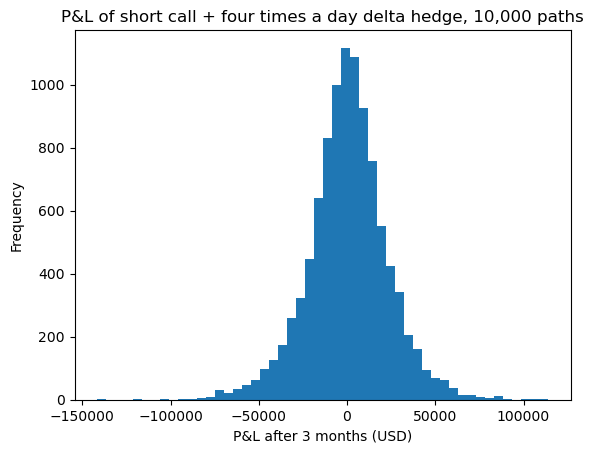

mean P&L = 432.15001185267744
std P&L  = 22677.743804862042


In [24]:
#d)
mu = 0.05
M = 2000
n_paths, n_steps = 10000, 91
dt = T / n_steps

# Simulate index paths
S = np.zeros((n_paths, n_steps + 1))
S[:, 0] = S0
for i in range(n_steps):
    Z = np.random.randn(n_paths)
    S[:, i + 1] = S[:, i] * np.exp((mu - 0.5 * sigma**2) * dt + sigma * np.sqrt(dt) * Z)

# Hedge at t = 0
d1 = (np.log(S0 / K) + (r + 0.5 * sigma**2) * T) / (sigma * np.sqrt(T))
delta = M * norm.cdf(d1) * np.ones(n_paths)
cash = M * C - delta * S0

# Weekly rebalancing
for i in range(1, n_steps):
    cash = cash * np.exp(r * dt)
    d1 = (np.log(S[:, i] / K) + (r + 0.5 * sigma**2) * (T - i * dt)) / (sigma * np.sqrt(T - i * dt))
    new_delta = M * norm.cdf(d1)
    cash = cash - (new_delta - delta) * S[:, i]
    delta = new_delta

# Maturity
cash = cash * np.exp(r * dt)
pnl = delta * S[:, -1] + cash - M * np.maximum(S[:, -1] - K, 0)

plt.hist(pnl, bins=50)
plt.xlabel("P&L after 3 months (USD)")
plt.ylabel("Frequency")
plt.title("P&L of short call + daily delta hedge, 10,000 paths")
plt.show()

print("mean P&L =", np.mean(pnl))
print("std P&L  =", np.std(pnl))

# 4 times a day
mu = 0.05
M = 2000
n_paths, n_steps = 10000, 364
dt = T / n_steps

# Simulate index paths
S = np.zeros((n_paths, n_steps + 1))
S[:, 0] = S0
for i in range(n_steps):
    Z = np.random.randn(n_paths)
    S[:, i + 1] = S[:, i] * np.exp((mu - 0.5 * sigma**2) * dt + sigma * np.sqrt(dt) * Z)

# Hedge at t = 0
d1 = (np.log(S0 / K) + (r + 0.5 * sigma**2) * T) / (sigma * np.sqrt(T))
delta = M * norm.cdf(d1) * np.ones(n_paths)
cash = M * C - delta * S0

# Weekly rebalancing
for i in range(1, n_steps):
    cash = cash * np.exp(r * dt)
    d1 = (np.log(S[:, i] / K) + (r + 0.5 * sigma**2) * (T - i * dt)) / (sigma * np.sqrt(T - i * dt))
    new_delta = M * norm.cdf(d1)
    cash = cash - (new_delta - delta) * S[:, i]
    delta = new_delta

# Maturity
cash = cash * np.exp(r * dt)
pnl = delta * S[:, -1] + cash - M * np.maximum(S[:, -1] - K, 0)

plt.hist(pnl, bins=50)
plt.xlabel("P&L after 3 months (USD)")
plt.ylabel("Frequency")
plt.title("P&L of short call + four times a day delta hedge, 10,000 paths")
plt.show()

print("mean P&L =", np.mean(pnl))
print("std P&L  =", np.std(pnl))

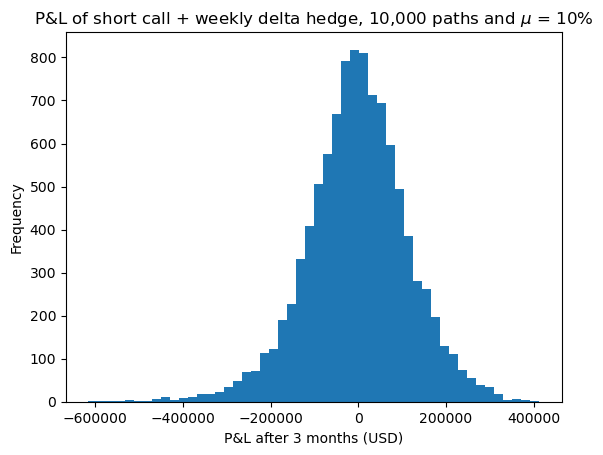

mean P&L = -2183.528213162009
std P&L  = 116313.17139094713


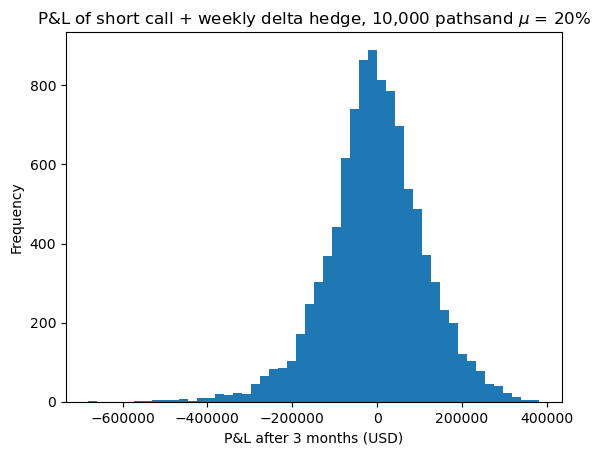

mean P&L = -3929.6728787293105
std P&L  = 115149.8660009493


In [21]:
#e)
mu = 0.1
M = 2000
n_paths, n_steps = 10000, 13
dt = T / n_steps

# Simulate index paths
S = np.zeros((n_paths, n_steps + 1))
S[:, 0] = S0
for i in range(n_steps):
    Z = np.random.randn(n_paths)
    S[:, i + 1] = S[:, i] * np.exp((mu - 0.5 * sigma**2) * dt + sigma * np.sqrt(dt) * Z)

# Hedge at t = 0
d1 = (np.log(S0 / K) + (r + 0.5 * sigma**2) * T) / (sigma * np.sqrt(T))
delta = M * norm.cdf(d1) * np.ones(n_paths)
cash = M * C - delta * S0

# Weekly rebalancing
for i in range(1, n_steps):
    cash = cash * np.exp(r * dt)
    d1 = (np.log(S[:, i] / K) + (r + 0.5 * sigma**2) * (T - i * dt)) / (sigma * np.sqrt(T - i * dt))
    new_delta = M * norm.cdf(d1)
    cash = cash - (new_delta - delta) * S[:, i]
    delta = new_delta

# Maturity
cash = cash * np.exp(r * dt)
pnl = delta * S[:, -1] + cash - M * np.maximum(S[:, -1] - K, 0)

plt.hist(pnl, bins=50)
plt.xlabel("P&L after 3 months (USD)")
plt.ylabel("Frequency")
plt.title("P&L of short call + weekly delta hedge, 10,000 paths and $\mu$ = 10%")
plt.show()

print("mean P&L =", np.mean(pnl))
print("std P&L  =", np.std(pnl))

#mu = 0.20

mu = 0.2
M = 2000
n_paths, n_steps = 10000, 13
dt = T / n_steps

# Simulate index paths
S = np.zeros((n_paths, n_steps + 1))
S[:, 0] = S0
for i in range(n_steps):
    Z = np.random.randn(n_paths)
    S[:, i + 1] = S[:, i] * np.exp((mu - 0.5 * sigma**2) * dt + sigma * np.sqrt(dt) * Z)

# Hedge at t = 0
d1 = (np.log(S0 / K) + (r + 0.5 * sigma**2) * T) / (sigma * np.sqrt(T))
delta = M * norm.cdf(d1) * np.ones(n_paths)
cash = M * C - delta * S0

# Weekly rebalancing
for i in range(1, n_steps):
    cash = cash * np.exp(r * dt)
    d1 = (np.log(S[:, i] / K) + (r + 0.5 * sigma**2) * (T - i * dt)) / (sigma * np.sqrt(T - i * dt))
    new_delta = M * norm.cdf(d1)
    cash = cash - (new_delta - delta) * S[:, i]
    delta = new_delta

# Maturity
cash = cash * np.exp(r * dt)
pnl = delta * S[:, -1] + cash - M * np.maximum(S[:, -1] - K, 0)

plt.hist(pnl, bins=50)
plt.xlabel("P&L after 3 months (USD)")
plt.ylabel("Frequency")
plt.title("P&L of short call + weekly delta hedge, 10,000 pathsand $\mu$ = 20%")
plt.show()

print("mean P&L =", np.mean(pnl))
print("std P&L  =", np.std(pnl))

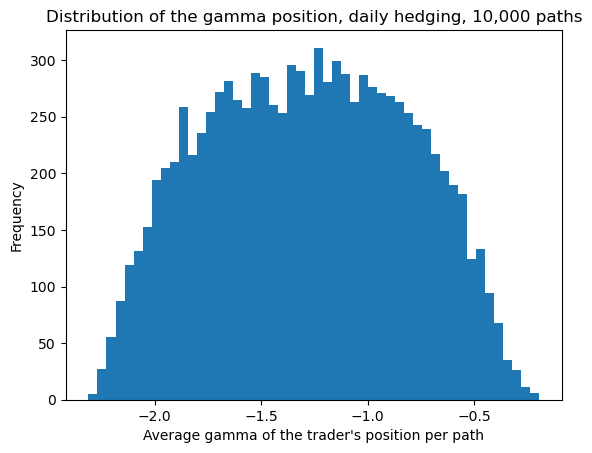

correlation(avg gamma, |P&L|) = -0.3896487789703527


In [30]:
#g) 
mu = 0.05
M = 2000
n_paths, n_steps = 10000, 91
dt = T / n_steps

# Simulate index paths
S = np.zeros((n_paths, n_steps + 1))
S[:, 0] = S0
for i in range(n_steps):
    Z = np.random.randn(n_paths)
    S[:, i + 1] = S[:, i] * np.exp((mu - 0.5 * sigma**2) * dt + sigma * np.sqrt(dt) * Z)

delta = np.zeros(n_paths)
cash = M * C * np.ones(n_paths)
gamma = np.zeros((n_paths, n_steps))

for i in range(n_steps):
    tau = T - i * dt
    d1 = (np.log(S[:, i] / K) + (r + 0.5 * sigma**2) * tau) / (sigma * np.sqrt(tau))
    new_delta = M * norm.cdf(d1)
    gamma[:, i] = -M * norm.pdf(d1) / (S[:, i] * sigma * np.sqrt(tau))  # short position
    cash = cash - (new_delta - delta) * S[:, i]
    delta = new_delta
    cash = cash * np.exp(r * dt)

pnl = delta * S[:, -1] + cash - M * np.maximum(S[:, -1] - K, 0)
avg_gamma = gamma.mean(axis=1)

plt.hist(avg_gamma, bins=50)
plt.xlabel("Average gamma of the trader's position per path")
plt.ylabel("Frequency")
plt.title("Distribution of the gamma position, daily hedging, 10,000 paths")
plt.show()

print("correlation(avg gamma, |P&L|) =", np.corrcoef(avg_gamma, np.abs(pnl))[0, 1])

In [33]:
#h)
delta = np.zeros(n_paths)
cash = np.zeros(n_paths)

for i in range(n_steps):
    tau = T - i * dt
    d1 = (np.log(S[:, i] / K) + (r + 0.5 * sigma**2) * tau) / (sigma * np.sqrt(tau))
    new_delta = norm.cdf(d1) - 1
    cash = cash - (new_delta - delta) * S[:, i]
    delta = new_delta
    cash = cash * np.exp(r * dt)

W = delta * S[:, -1] + cash                    # trading result of the hedge
payoff_put = np.maximum(K - S[:, -1], 0)
V0 = np.exp(-r * T) * (payoff_put - W)         # initial capital needed per path
P_rep = V0.mean()

print("Put price (replication) =", P_rep)

# Put-call parity: C - P = S0 - K e^{-rT}
print("C - P          =", C - P_rep)
print("S0 - K e^(-rT) =", S0 - K * np.exp(-r * T))

Put price (replication) = 251.64540466009183
C - P          = -7.499906900119896
S0 - K e^(-rT) = -7.307692307691468


In [32]:
#i) 
Z = np.random.randn(n_paths)
ST = S0 * np.exp((r - 0.5 * sigma**2) * T + sigma * np.sqrt(T) * Z)
P_rn = np.exp(-r * T) * np.mean(np.maximum(K - ST, 0))
print("Put price (risk-neutral) =", P_rn)

Put price (risk-neutral) = 249.8860397249977
